# Implementacion Algoritmo - Greedy

In [218]:
import time
import heapq
from itertools import product, permutations

In [219]:
class Tarea:
    def __init__(self, id, tiempo, prioridad, dependencias):
        self.id = id
        self.tiempo = tiempo
        self.prioridad = prioridad
        self.dependencias = dependencias

    def __repr__(self):
        return str(self.id)

In [220]:
def asignar_tareas(tareas, num_servidores, criterio="prioridad"):
    servidores = [(0, i, []) for i in range(num_servidores)]
    heapq.heapify(servidores)

    fin_tarea = {}             
    pendientes = list(tareas)   

    while pendientes:
        disponibles = [t for t in pendientes if all(dep in fin_tarea for dep in t.dependencias)]

        tarea = max(disponibles, key=lambda t: getattr(t, criterio))

        carga, id_servidor, lista = heapq.heappop(servidores)

        fin_deps = max((fin_tarea[dep] for dep in tarea.dependencias), default=0)
        inicio = max(carga, fin_deps)
        fin = inicio + tarea.tiempo

        lista.append(tarea)
        fin_tarea[tarea.id] = fin
        heapq.heappush(servidores, (fin, id_servidor, lista))
        pendientes.remove(tarea)

    tiempo_total = max(carga for carga, _, _ in servidores)
    asignacion = {id_s: lista for _, id_s, lista in sorted(servidores, key=lambda s: s[1])}
    return tiempo_total, asignacion

# Pruebas

In [221]:
servidores_pequeño = 2
tareas_pequeño = [
    Tarea("A", 5, 2, []),
    Tarea("B", 3, 1, ["A"]),
    Tarea("C", 4, 3, ["A"]),
    Tarea("D", 2, 1, ["B", "C"]),
]


In [222]:
servidores_mediano = 3
tareas_mediano = [
    Tarea("B", 13, 1, []),
    Tarea("C", 5, 3, ["A"]),
    Tarea("A", 8, 2, []),
    Tarea("D", 5, 2, ["A"]),
    Tarea("E", 4, 1, ["B", "C"]),
    Tarea("F", 6, 2, ["C"]),
    Tarea("G", 8, 2, ["E", "A"]),
    Tarea("H", 10, 2, ["D", "E", "F"]),
    Tarea("I", 7, 3, ["G"]),
]

In [223]:
servidores_grande = 3
tareas_grande = [
    Tarea("B", 13, 1, []),
    Tarea("C", 5, 3, ["A"]),
    Tarea("A", 8, 2, []),
    Tarea("D", 5, 2, ["A"]),
    Tarea("E", 4, 1, ["B", "C"]),
    Tarea("F", 6, 2, ["C"]),
    Tarea("G", 8, 2, ["E", "A"]),
    Tarea("H", 10, 2, ["D", "E", "F"]),
    Tarea("I", 7, 3, ["G"]),
    Tarea("J", 9, 1, ["B"]),
]

In [224]:
servidores_xl = 3
tareas_xl = [
    Tarea("B", 13, 1, []),
    Tarea("C", 5, 3, ["A"]),
    Tarea("A", 8, 2, []),
    Tarea("D", 5, 2, ["A"]),
    Tarea("E", 4, 1, ["B", "C"]),
    Tarea("F", 6, 2, ["C"]),
    Tarea("G", 8, 2, ["E", "A"]),
    Tarea("H", 10, 2, ["D", "E", "F"]),
    Tarea("I", 7, 3, ["G"]),
    Tarea("J", 9, 1, ["B"]),
    Tarea("K", 6, 2, []),
    Tarea("L", 11, 3, ["K"]),
    Tarea("M", 4, 1, ["J", "K"]),
    Tarea("N", 7, 2, ["H"]),
    Tarea("O", 3, 3, ["L", "F"]),
    Tarea("P", 12, 1, ["M"]),
    Tarea("Q", 5, 2, ["I", "O"]),
    Tarea("R", 9, 3, ["N", "P"]),
    Tarea("S", 2, 1, ["Q"]),
    Tarea("T", 8, 2, ["R", "S"]),
]

In [227]:
casos = [
    ("Pequeño", tareas_pequeño, servidores_pequeño),
    ("Mediano", tareas_mediano, servidores_mediano),
    ("Grande", tareas_grande, servidores_grande),
    ("Muy Grande", tareas_xl, servidores_xl),
]

for nombre, tareas, servidores in casos:
    inicio = time.perf_counter()
    resultado = asignar_tareas(tareas, servidores)
    fin = time.perf_counter()
    print(f"{nombre}: (Greedy) {resultado}")
    print(f"Tiempo: {fin - inicio:.6f} segundos\n")

Pequeño: (Greedy) (11, {0: [A, B, D], 1: [C]})
Tiempo: 0.000022 segundos

Mediano: (Greedy) (45, {0: [A, F, G], 1: [C, B, I], 2: [D, E, H]})
Tiempo: 0.000026 segundos

Grande: (Greedy) (47, {0: [A, F, G, J], 1: [C, B, I], 2: [D, E, H]})
Tiempo: 0.000026 segundos

Muy Grande: (Greedy) (93, {0: [A, F, O, I, J, R], 1: [C, K, B, G, N, M, S, T], 2: [D, L, E, H, Q, P]})
Tiempo: 0.000060 segundos



# Graficas

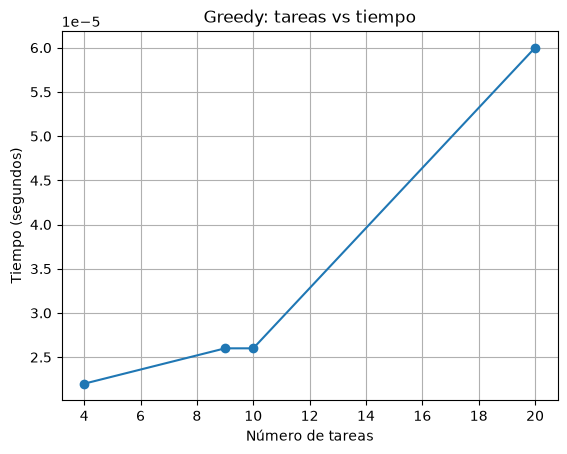

In [232]:
import matplotlib.pyplot as plt

tareas = [4, 9, 10, 20]
tiempos = [0.000022 , 0.000026, 0.000026, 0.000060]

plt.plot(tareas, tiempos, marker="o")
plt.xlabel("Número de tareas")
plt.ylabel("Tiempo (segundos)")
plt.title("Greedy: tareas vs tiempo")
plt.grid(True)
plt.show()